# Deep Learning for Finance - Group Work Project 3: Data Leakage and Walk-Forward Backtesting (MLP, LSTM, CNN-GAF)

# Step 1

## 1a

[*********************100%***********************]  1 of 1 completed


Number of observations: 2000
Date range: 2018-01-22 to 2026-01-05
            Return    LogReturn
count  1999.000000  1999.000000
mean      0.000583     0.000507
std       0.012286     0.012314
min      -0.109424    -0.115886
25%      -0.004362    -0.004372
50%       0.000842     0.000841
75%       0.006481     0.006460
max       0.105019     0.099863


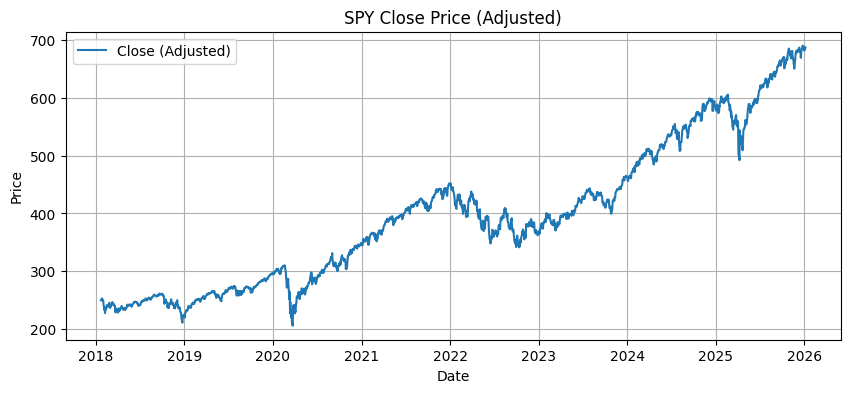

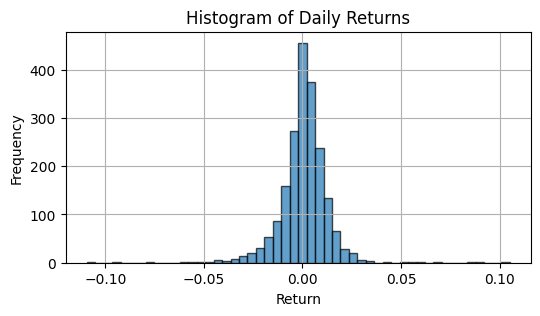

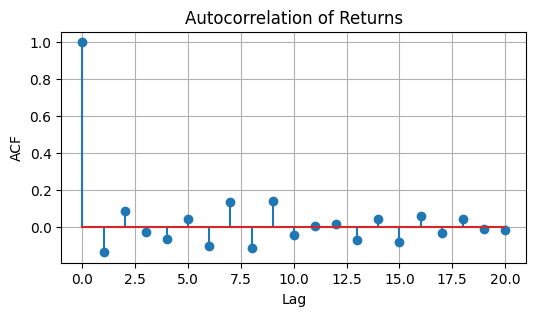

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set seed for reproducibility
np.random.seed(0)

import os
# Force re-download and re-creation of SPY.csv to prevent issues from old/corrupt files.
if os.path.exists('SPY.csv'):
    os.remove('SPY.csv')

# Fallback: if the local CSV is missing, download SPY data using yfinance.
if not os.path.exists('SPY.csv'): # This condition will now always be true after the removal.
    try:
        import yfinance as yf
        # Ensure auto_adjust is True to get adjusted close price in 'Close' column
        df_y = yf.download('SPY', start='2000-01-01', auto_adjust=True)
        df_y = df_y.reset_index()

        # Handle potential multi-level columns from yfinance.
        # Based on the kernel state, df_y can have MultiIndex columns like (Price, Ticker).
        # We need to flatten these to simple column names.
        if isinstance(df_y.columns, pd.MultiIndex):
            # Take the first level of the MultiIndex as the primary column names.
            # This is common for yfinance output when group_by_ticker is implicit
            # and the ticker symbol is in the second level, e.g. ('Open', 'SPY').
            df_y.columns = df_y.columns.get_level_values(0)

        # After flattening and reset_index, the 'Date' column might be named 'level_0'
        # if the original index had no name. Rename it to 'Date' if this is the case.
        if 'level_0' in df_y.columns:
            df_y.rename(columns={'level_0': 'Date'}, inplace=True)

        # Select the standard columns and save to CSV.
        # This explicitly ensures the CSV has the expected column names and order.
        clean_df = df_y[['Date', 'Open', 'High', 'Low', 'Close', 'Volume']].copy()
        clean_df.to_csv('SPY.csv', index=False)
    except Exception as e:
        # Re-raise the exception with a clear message for the user.
        raise FileNotFoundError(f'Missing SPY.csv file and failed to download from yfinance: {e}') from e

# Read data
data = pd.read_csv('SPY.csv', parse_dates=['Date'])

# Clean: sort by date and drop duplicates
data = data.sort_values('Date').drop_duplicates('Date').reset_index(drop=True)

# Take the 2,000 most recent observations to satisfy the assignment requirement
if len(data) > 2000:
    data = data.tail(2000).reset_index(drop=True)

# Ensure 'Close' column is truly numeric after reading from CSV
data['Close'] = pd.to_numeric(data['Close'], errors='coerce')
data = data.dropna(subset=['Close']) # Drop rows where Close might be NaN due to coercion error

# Compute simple returns and log returns
data['Return'] = data['Close'].astype(float).pct_change()
data['LogReturn'] = np.log(data['Close'].astype(float)).diff()

# Display basic information
print(f'Number of observations: {len(data)}')
print(f'Date range: {data["Date"].iloc[0].date()} to {data["Date"].iloc[-1].date()}')
print(data[["Return", "LogReturn"]].describe())

# Plot Adj Close price
plt.figure(figsize=(10, 4))
plt.plot(data['Date'], data['Close'], label='Close (Adjusted)')
plt.xlabel('Date'); plt.ylabel('Price')
plt.title('SPY Close Price (Adjusted)')
plt.legend(); plt.grid(True)
plt.show()

# Histogram of daily returns
plt.figure(figsize=(6, 3))
plt.hist(data['Return'].dropna(), bins=50, alpha=0.7, edgecolor='k')
plt.title('Histogram of Daily Returns')
plt.xlabel('Return'); plt.ylabel('Frequency')
plt.grid(True)
plt.show()

# Simple autocorrelation for 20 lags
returns_series = data['Return'].dropna().values
max_lag = 20
acf = [1.0] + [np.corrcoef(returns_series[:-lag], returns_series[lag:])[0,1] for lag in range(1, max_lag+1)]
plt.figure(figsize=(6,3))
plt.stem(range(max_lag + 1), acf)
plt.title('Autocorrelation of Returns')
plt.xlabel('Lag'); plt.ylabel('ACF')
plt.grid(True)
plt.show()

## 1b

In [ ]:
# Parameters
window_size = 10  # number of lags used as features
k_forward = 5     # label based on k-day cumulative return

# Prepare return series (drop initial NaN from data)
returns = data['Return'].dropna().values

# Build features (past window) and k-day forward cumulative returns
features = []
fwd_k_returns = []
idx_positions = []
for i in range(window_size + k_forward, len(returns)):
    idx_positions.append(i)
    past_window = returns[i - k_forward - window_size : i - k_forward]
    future_window = returns[i - k_forward : i]
    features.append(past_window)
    fwd_k_returns.append(np.prod(1 + future_window) - 1)

features = np.array(features)
fwd_k_returns = np.array(fwd_k_returns)

# Intentionally build labels using a global threshold computed over the entire sample (leakage)
threshold = np.quantile(fwd_k_returns, 0.6)
labels = (fwd_k_returns > threshold).astype(int)

# Intentional leakage: normalise features using the mean and std over the entire dataset
mean_feat = features.mean(axis=0, keepdims=False)
std_feat = features.std(axis=0, keepdims=False) + 1e-8
features_norm = (features - mean_feat) / std_feat

# Chronological train/test split (70/30)
split = int(0.7 * len(features_norm))
X_train, X_test = features_norm[:split], features_norm[split:]
y_train, y_test = labels[:split], labels[split:]
fwd_k_train, fwd_k_test = fwd_k_returns[:split], fwd_k_returns[split:]

# Leakage proof: count how many training labels use forward returns that overlap the test period
idx_positions = np.array(idx_positions)
test_start_index = idx_positions[split]  # first idx of test set
leak_count = 0
for i in range(split):
    start_label = idx_positions[i] - k_forward
    end_label = idx_positions[i] - 1
    if end_label >= test_start_index:
        leak_count += 1
print(f'Training samples whose labels incorporate test-period returns (leakage count): {leak_count} out of {split}')

# Display basic shapes
print(f'Number of training samples: {len(X_train)}, Number of test samples: {len(X_test)}')

Training samples whose labels incorporate test-period returns (leakage count): 0 out of 1388
Number of training samples: 1388, Number of test samples: 596


## 1.c

In [ ]:
# ===== MLP =====
np.random.seed(0)  # ensure reproducibility
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
input_dim = window_size
hidden_sizes = [32, 16]
# Initialize parameters
W1 = np.random.randn(input_dim, hidden_sizes[0]) * 0.1
b1 = np.zeros(hidden_sizes[0])
W2 = np.random.randn(hidden_sizes[0], hidden_sizes[1]) * 0.1
b2 = np.zeros(hidden_sizes[1])
W3 = np.random.randn(hidden_sizes[1], 1) * 0.1
b3 = np.zeros(1)

def relu(x):
    return np.maximum(0, x)

def sigmoid_stable(z):
    # Stable sigmoid with clipping to avoid overflow
    z = np.clip(z, -50, 50)
    return 1 / (1 + np.exp(-z))

# Train the MLP
lr_mlp = 0.01
epochs_mlp = 30
for epoch in range(epochs_mlp):
    # Forward
    z1 = X_train @ W1 + b1
    a1 = relu(z1)
    z2 = a1 @ W2 + b2
    a2 = relu(z2)
    z3 = a2 @ W3 + b3
    y_hat = sigmoid_stable(z3)

    # Loss
    y_train_col = y_train.reshape(-1,1)
    loss = -np.mean(y_train_col * np.log(y_hat + 1e-8) + (1 - y_train_col) * np.log(1 - y_hat + 1e-8))

    # Backward
    dz3 = y_hat - y_train_col
    dW3 = a2.T @ dz3 / len(X_train)
    db3 = dz3.mean(axis=0)
    da2 = dz3 @ W3.T
    dz2 = da2 * (z2 > 0)
    dW2 = a1.T @ dz2 / len(X_train)
    db2 = dz2.mean(axis=0)
    da1 = dz2 @ W2.T
    dz1 = da1 * (z1 > 0)
    dW1 = X_train.T @ dz1 / len(X_train)
    db1 = dz1.mean(axis=0)

    # Update
    W3 -= lr_mlp * dW3
    b3 -= lr_mlp * db3
    W2 -= lr_mlp * dW2
    b2 -= lr_mlp * db2
    W1 -= lr_mlp * dW1
    b1 -= lr_mlp * db1

    if (epoch + 1) % 5 == 0:
        print(f'MLP epoch {epoch+1}/{epochs_mlp}, loss={loss:.4f}')

# Prediction function
def mlp_predict(X):
    z1 = X @ W1 + b1
    a1 = relu(z1)
    z2 = a1 @ W2 + b2
    a2 = relu(z2)
    z3 = a2 @ W3 + b3
    return sigmoid_stable(z3)[:,0]

mlp_probs = mlp_predict(X_test)
mlp_preds = (mlp_probs > 0.5).astype(int)
mlp_acc = accuracy_score(y_test, mlp_preds)
print('MLP test accuracy:', round(mlp_acc, 3))
cm_mlp = confusion_matrix(y_test, mlp_preds)
print('MLP Confusion Matrix:')
print(cm_mlp)
print('MLP Classification Report:')
print(classification_report(y_test, mlp_preds, digits=3))

MLP epoch 5/30, loss=0.6939
MLP epoch 10/30, loss=0.6934
MLP epoch 15/30, loss=0.6928
MLP epoch 20/30, loss=0.6923
MLP epoch 25/30, loss=0.6918
MLP epoch 30/30, loss=0.6913
MLP test accuracy: 0.601
MLP Confusion Matrix:
[[339  19]
 [219  19]]
MLP Classification Report:
              precision    recall  f1-score   support

           0      0.608     0.947     0.740       358
           1      0.500     0.080     0.138       238

    accuracy                          0.601       596
   macro avg      0.554     0.513     0.439       596
weighted avg      0.565     0.601     0.500       596



In [ ]:
# ===== LSTM =====
np.random.seed(0)  # ensure reproducibility
from sklearn.metrics import confusion_matrix, classification_report
hidden_size = 16
# Initialize parameters for LSTM (input, forget, output and candidate g)
W_i = np.random.randn(hidden_size) * 0.1
U_i = np.random.randn(hidden_size, hidden_size) * 0.1
b_i = np.zeros(hidden_size)

W_f = np.random.randn(hidden_size) * 0.1
U_f = np.random.randn(hidden_size, hidden_size) * 0.1
b_f = np.zeros(hidden_size)

W_o = np.random.randn(hidden_size) * 0.1
U_o = np.random.randn(hidden_size, hidden_size) * 0.1
b_o = np.zeros(hidden_size)

W_g = np.random.randn(hidden_size) * 0.1
U_g = np.random.randn(hidden_size, hidden_size) * 0.1
b_g = np.zeros(hidden_size)

# Output layer
W_y = np.random.randn(hidden_size) * 0.1
b_y = 0.0

def sigmoid(x):
    x = np.clip(x, -50, 50)
    return 1 / (1 + np.exp(-x))

epochs_lstm = 10
lr_lstm = 0.001
grad_clip = 5.0
for epoch in range(epochs_lstm):
    # gradient accumulators
    dW_i = np.zeros_like(W_i); dU_i = np.zeros_like(U_i); db_i = np.zeros_like(b_i)
    dW_f = np.zeros_like(W_f); dU_f = np.zeros_like(U_f); db_f = np.zeros_like(b_f)
    dW_o = np.zeros_like(W_o); dU_o = np.zeros_like(U_o); db_o = np.zeros_like(b_o)
    dW_g = np.zeros_like(W_g); dU_g = np.zeros_like(U_g); db_g = np.zeros_like(b_g)
    dW_y = np.zeros_like(W_y); db_y_acc = 0.0
    total_loss = 0.0
    for i in range(len(X_train)):
        x_seq = X_train[i]  # length = window_size
        y_true = y_train[i]
        # forward pass storing values
        i_list, f_list, o_list, g_list, c_list, h_list, c_prev_list, h_prev_list = [], [], [], [], [], [], [], []
        h_prev = np.zeros(hidden_size)
        c_prev = np.zeros(hidden_size)
        for x_t in x_seq:
            i_t = sigmoid(W_i * x_t + U_i @ h_prev + b_i)
            f_t = sigmoid(W_f * x_t + U_f @ h_prev + b_f)
            o_t = sigmoid(W_o * x_t + U_o @ h_prev + b_o)
            g_t = np.tanh(W_g * x_t + U_g @ h_prev + b_g)
            c_t = f_t * c_prev + i_t * g_t
            h_t = o_t * np.tanh(c_t)
            # store
            i_list.append(i_t); f_list.append(f_t); o_list.append(o_t); g_list.append(g_t); c_list.append(c_t); h_list.append(h_t); c_prev_list.append(c_prev); h_prev_list.append(h_prev)
            # update
            h_prev = h_t
            c_prev = c_t
        # Output layer
        h_last = h_list[-1]
        z_out = W_y @ h_last + b_y
        y_hat = sigmoid(z_out)
        # Loss
        total_loss += - (y_true * np.log(y_hat + 1e-8) + (1 - y_true) * np.log(1 - y_hat + 1e-8))
        # gradients output layer
        dz = y_hat - y_true
        dW_y += h_last * dz
        db_y_acc += dz
        dh_next = W_y * dz
        d_c_next = np.zeros(hidden_size)
        # Backprop through time
        for t in reversed(range(window_size)):
            h_t = h_list[t]
            c_t = c_list[t]
            i_t = i_list[t]
            f_t = f_list[t]
            o_t = o_list[t]
            g_t = g_list[t]
            c_prev_t = c_prev_list[t]
            h_prev_t = h_prev_list[t]
            # dh includes gradient from future hidden units
            dh = dh_next.copy()
            # d_o = dh * tanh(c_t) * sigmoid'(o_t)
            d_o = dh * np.tanh(c_t) * o_t * (1 - o_t)
            # d_c from h_t
            d_c = dh * o_t * (1 - np.tanh(c_t) ** 2) + d_c_next
            # d_f = d_c * c_prev * sigmoid'(f_t)
            d_f = d_c * c_prev_t * f_t * (1 - f_t)
            # d_i = d_c * g_t * sigmoid'(i_t)
            d_i = d_c * g_t * i_t * (1 - i_t)
            # d_g = d_c * i_t * tanh'(g_t)
            d_g = d_c * i_t * (1 - g_t ** 2)
            # Gradient w.r.t parameters
            x_t_val = x_seq[t]
            dW_i += d_i * x_t_val
            dU_i += np.outer(d_i, h_prev_t)
            db_i += d_i
            dW_f += d_f * x_t_val
            dU_f += np.outer(d_f, h_prev_t)
            db_f += d_f
            dW_o += d_o * x_t_val
            dU_o += np.outer(d_o, h_prev_t)
            db_o += d_o
            dW_g += d_g * x_t_val
            dU_g += np.outer(d_g, h_prev_t)
            db_g += d_g
            # Update dh_next and d_c_next for next step
            dh_prev = (U_i.T @ d_i + U_f.T @ d_f + U_o.T @ d_o + U_g.T @ d_g)
            d_c_prev = d_c * f_t
            dh_next = dh_prev
            d_c_next = d_c_prev
    # Normalise gradients by number of samples
    n = len(X_train)
    dW_i /= n; dU_i /= n; db_i /= n
    dW_f /= n; dU_f /= n; db_f /= n
    dW_o /= n; dU_o /= n; db_o /= n
    dW_g /= n; dU_g /= n; db_g /= n
    dW_y /= n; db_y_acc /= n; total_loss /= n
    # Gradient clipping
    for grad in [dW_i, dU_i, db_i, dW_f, dU_f, db_f, dW_o, dU_o, db_o, dW_g, dU_g, db_g, dW_y]:
        np.clip(grad, -grad_clip, grad_clip, out=grad)
    db_y_acc = np.clip(db_y_acc, -grad_clip, grad_clip)
    # Update parameters
    W_i -= lr_lstm * dW_i; U_i -= lr_lstm * dU_i; b_i -= lr_lstm * db_i
    W_f -= lr_lstm * dW_f; U_f -= lr_lstm * dU_f; b_f -= lr_lstm * db_f
    W_o -= lr_lstm * dW_o; U_o -= lr_lstm * dU_o; b_o -= lr_lstm * db_o
    W_g -= lr_lstm * dW_g; U_g -= lr_lstm * dU_g; b_g -= lr_lstm * db_g
    W_y -= lr_lstm * dW_y; b_y -= lr_lstm * db_y_acc
    if (epoch + 1) % 2 == 0:
        print(f'LSTM epoch {epoch+1}/{epochs_lstm}, loss={total_loss:.4f}')

# Prediction function for LSTM
def lstm_predict(X):
    preds = []
    for seq in X:
        h_prev = np.zeros(hidden_size)
        c_prev = np.zeros(hidden_size)
        for x_t in seq:
            i_t = sigmoid(W_i * x_t + U_i @ h_prev + b_i)
            f_t = sigmoid(W_f * x_t + U_f @ h_prev + b_f)
            o_t = sigmoid(W_o * x_t + U_o @ h_prev + b_o)
            g_t = np.tanh(W_g * x_t + U_g @ h_prev + b_g)
            c_t = f_t * c_prev + i_t * g_t
            h_t = o_t * np.tanh(c_t)
            h_prev = h_t
            c_prev = c_t
        z = W_y @ h_prev + b_y
        y_hat = sigmoid(z)
        preds.append(float(y_hat))
    return np.array(preds)

lstm_probs = lstm_predict(X_test)
lstm_preds = (lstm_probs > 0.5).astype(int)
lstm_acc = accuracy_score(y_test, lstm_preds)
print('LSTM test accuracy:', round(lstm_acc, 3))
cm_lstm = confusion_matrix(y_test, lstm_preds)
print('LSTM Confusion Matrix:')
print(cm_lstm)
print('LSTM Classification Report:')
print(classification_report(y_test, lstm_preds, digits=3))

LSTM epoch 2/10, loss=0.6932
LSTM epoch 4/10, loss=0.6932
LSTM epoch 6/10, loss=0.6932
LSTM epoch 8/10, loss=0.6931
LSTM epoch 10/10, loss=0.6931
LSTM test accuracy: 0.508
LSTM Confusion Matrix:
[[210 148]
 [145  93]]
LSTM Classification Report:
              precision    recall  f1-score   support

           0      0.592     0.587     0.589       358
           1      0.386     0.391     0.388       238

    accuracy                          0.508       596
   macro avg      0.489     0.489     0.489       596
weighted avg      0.509     0.508     0.509       596



In [ ]:
# ===== CNN-GAF =====
np.random.seed(0)  # ensure reproducibility
from sklearn.metrics import confusion_matrix, classification_report
# Function to compute Gramian Angular Summation Field
def compute_gasf(window):
    # normalize window to [-1, 1]
    w_min, w_max = window.min(), window.max()
    if w_max - w_min == 0:
        scaled = np.zeros_like(window)
    else:
        scaled = (window - w_min) / (w_max - w_min) * 2 - 1
    scaled = np.clip(scaled, -1, 1)
    phi = np.arccos(scaled)
    return np.cos(phi[:, None] + phi[None, :])

# Convert features into GAF images
images = np.array([compute_gasf(win) for win in features])
X_train_img = images[:split]; X_test_img = images[split:]

kernel_size = 3
out_dim = window_size - kernel_size + 1
# Initialize parameters for CNN
Wc = np.random.randn(kernel_size, kernel_size) * 0.1
bc_cnn = 0.0
W_fc = np.random.randn(out_dim * out_dim, 1) * 0.1
b_fc = 0.0

lr_cnn = 0.001
epochs_cnn = 5
for epoch in range(epochs_cnn):
    dWc = np.zeros_like(Wc)
    dbc = 0.0
    dWfc = np.zeros_like(W_fc)
    dbfc = 0.0
    total_loss = 0
    for i in range(len(X_train_img)):
        img = X_train_img[i]
        y_true = y_train[i]
        # Convolution
        conv_out = np.zeros((out_dim, out_dim))
        for r in range(out_dim):
            for c in range(out_dim):
                conv_out[r, c] = (img[r:r+kernel_size, c:c+kernel_size] * Wc).sum() + bc_cnn
        relu_out = np.maximum(conv_out, 0)
        flat = relu_out.flatten().reshape(-1,1)
        z = W_fc.T @ flat + b_fc
        y_hat = sigmoid_stable(z)
        total_loss += - (y_true * np.log(y_hat + 1e-8) + (1 - y_true) * np.log(1 - y_hat + 1e-8))
        # Gradients
        dy = y_hat - y_true
        dWfc += flat * dy
        dbfc += dy
        dflat = W_fc * dy
        d_relu = dflat.reshape(out_dim, out_dim)
        d_conv = d_relu * (conv_out > 0)
        for r in range(out_dim):
            for c in range(out_dim):
                dWc += img[r:r+kernel_size, c:c+kernel_size] * d_conv[r, c]
                dbc += d_conv[r, c]
    # Normalise gradients
    n = len(X_train_img)
    dWc /= n; dbc /= n; dWfc /= n; dbfc /= n; total_loss /= n
    # Update
    Wc -= lr_cnn * dWc
    bc_cnn -= lr_cnn * dbc
    W_fc -= lr_cnn * dWfc
    b_fc -= lr_cnn * dbfc
    print(f'CNN epoch {epoch+1}/{epochs_cnn}, loss={float(total_loss):.4f}')
# Prediction function CNN
def cnn_predict(Ximgs):
    preds = []
    for img in Ximgs:
        conv_out = np.zeros((out_dim, out_dim))
        for r in range(out_dim):
            for c in range(out_dim):
                conv_out[r, c] = (img[r:r+kernel_size, c:c+kernel_size] * Wc).sum() + bc_cnn
        relu_out = np.maximum(conv_out, 0)
        flat = relu_out.flatten().reshape(-1,1)
        z = W_fc.T @ flat + b_fc
        y_hat = sigmoid_stable(z)
        preds.append(float(y_hat))
    return np.array(preds)

cnn_probs = cnn_predict(X_test_img)
cnn_preds = (cnn_probs > 0.5).astype(int)
cnn_acc = accuracy_score(y_test, cnn_preds)
print('CNN test accuracy:', round(cnn_acc, 3))
cm_cnn = confusion_matrix(y_test, cnn_preds)
print('CNN Confusion Matrix:')
print(cm_cnn)
print('CNN Classification Report:')
print(classification_report(y_test, cnn_preds, digits=3))

CNN epoch 1/5, loss=0.6940
CNN epoch 2/5, loss=0.6940
CNN epoch 3/5, loss=0.6940
CNN epoch 4/5, loss=0.6939
CNN epoch 5/5, loss=0.6939
CNN test accuracy: 0.502
CNN Confusion Matrix:
[[176 182]
 [115 123]]
CNN Classification Report:
              precision    recall  f1-score   support

           0      0.605     0.492     0.542       358
           1      0.403     0.517     0.453       238

    accuracy                          0.502       596
   macro avg      0.504     0.504     0.498       596
weighted avg      0.524     0.502     0.507       596



         TotalReturn  AnnReturn  Volatility    Sharpe  MaxDrawdown   HitRate
BuyHold     0.582804   0.212717    0.157307  1.307958    -0.185639  0.633333
MLP        -0.413503  -0.200770    0.157793 -1.338712    -0.451565  0.383333
LSTM        0.269585   0.105447    0.158769  0.710217    -0.148673  0.533333
CNN         0.054285   0.022451    0.159728  0.219937    -0.197432  0.566667


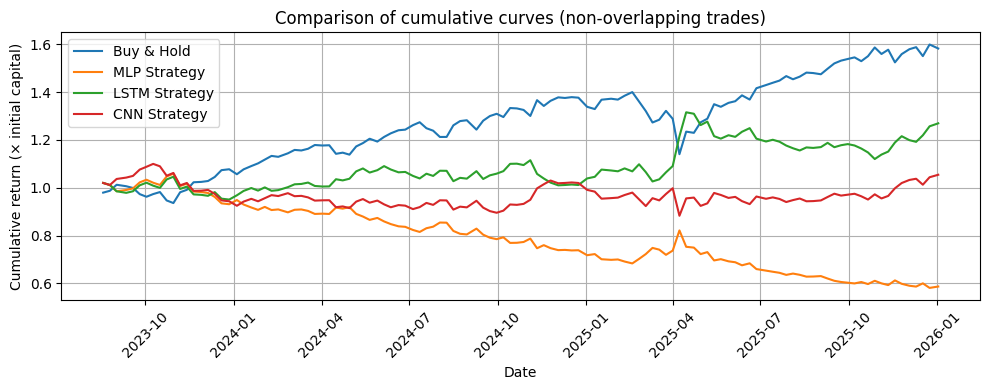

In [ ]:
# Prepare returns for test
# Use k-day compounded returns for backtest to match labels
test_returns = fwd_k_test

# Metric computation function
# Compute basic performance metrics from a series of k-day returns.
def compute_metrics(strategy_returns, k_forward):
    strategy_returns = np.array(strategy_returns)
    total_ret = np.prod(1 + strategy_returns) - 1
    freq = 252 / k_forward  # number of k-day periods per year
    ann_ret = (1 + total_ret) ** (freq / len(strategy_returns)) - 1
    vol = strategy_returns.std() * np.sqrt(freq)
    sharpe = (strategy_returns.mean() / (strategy_returns.std() + 1e-12)) * np.sqrt(freq)
    cum = np.cumprod(1 + strategy_returns)
    peak = np.maximum.accumulate(cum)
    drawdown = (cum - peak) / peak
    max_dd = drawdown.min()
    hit_rate = (strategy_returns > 0).mean()
    return {'TotalReturn': total_ret, 'AnnReturn': ann_ret, 'Volatility': vol,
            'Sharpe': sharpe, 'MaxDrawdown': max_dd, 'HitRate': hit_rate}

# Build signals for each model (+1 for long, -1 for short)
mlp_signal = 2 * mlp_preds - 1
lstm_signal = 2 * lstm_preds - 1
cnn_signal = 2 * cnn_preds - 1

# To avoid overlapping k-day returns, sample non-overlapping trades
stride = k_forward
trade_idx = np.arange(0, len(test_returns), stride)

# Apply transaction cost per trade (e.g. 0.05% per trade)
cost_bps = 0.0005

# Buy & Hold benchmark using k-day returns at non-overlapping intervals
bh_returns = test_returns[trade_idx]

# Strategy returns (signal * return minus cost)
mlp_returns_non = mlp_signal[trade_idx] * bh_returns - cost_bps * np.abs(mlp_signal[trade_idx])
lstm_returns_non = lstm_signal[trade_idx] * bh_returns - cost_bps * np.abs(lstm_signal[trade_idx])
cnn_returns_non = cnn_signal[trade_idx] * bh_returns - cost_bps * np.abs(cnn_signal[trade_idx])

# Compute metrics for each model and benchmark
metrics = {}
metrics['BuyHold'] = compute_metrics(bh_returns, k_forward)
metrics['MLP'] = compute_metrics(mlp_returns_non, k_forward)
metrics['LSTM'] = compute_metrics(lstm_returns_non, k_forward)
metrics['CNN'] = compute_metrics(cnn_returns_non, k_forward)

# Create DataFrame and display
metrics_df = pd.DataFrame(metrics).T
print(metrics_df)

# Plot cumulative curves using actual dates as x-axis
import matplotlib.dates as mdates
# Use idx_positions and split from previous cell

# test_positions correspond to end indices of each sample
# Retrieve positions for the test set and then select non-overlapping ones
test_positions = idx_positions[split:]
trade_positions = test_positions[trade_idx]
trade_dates = data['Date'].iloc[trade_positions].reset_index(drop=True)

cum_bh = np.cumprod(1 + bh_returns)
cum_mlp = np.cumprod(1 + mlp_returns_non)
cum_lstm = np.cumprod(1 + lstm_returns_non)
cum_cnn = np.cumprod(1 + cnn_returns_non)

plt.figure(figsize=(10,4))
plt.plot(trade_dates, cum_bh, label='Buy & Hold')
plt.plot(trade_dates, cum_mlp, label='MLP Strategy')
plt.plot(trade_dates, cum_lstm, label='LSTM Strategy')
plt.plot(trade_dates, cum_cnn, label='CNN Strategy')
plt.xlabel('Date')
plt.ylabel('Cumulative return (× initial capital)')
plt.title('Comparison of cumulative curves (non-overlapping trades)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 2


## 2.a

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

# --- 1. Define the GAF creation function ---
def create_gasf(window):
    """Computes Gramian Angular Summation Field for a given window."""
    # Ensure input is numpy array
    window = np.array(window)
    w_min, w_max = window.min(), window.max()

    # Handle constant windows to avoid division by zero
    if w_max - w_min == 0:
        scaled = np.zeros_like(window)
    else:
        # Normalize window to [-1, 1]
        scaled = (window - w_min) / (w_max - w_min) * 2 - 1

    # Clip to ensure values are within valid arccos range due to potential floating point errors
    scaled = np.clip(scaled, -1, 1)

    # Compute angles
    phi = np.arccos(scaled)

    # Compute GASF: cos(phi_i + phi_j) using broadcasting
    # The result is a 2D image of size (window_size x window_size)
    gasf = np.cos(phi[:, None] + phi[None, :])
    return gasf

# --- 2. Define the PyTorch MLP Model ---
class MLPModel(nn.Module):
    def __init__(self, input_dim, hidden_sizes=[32, 16]):
        super(MLPModel, self).__init__()
        # First hidden layer
        self.fc1 = nn.Linear(input_dim, hidden_sizes[0])
        # Second hidden layer
        self.fc2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
        # Output layer (1 unit for binary classification logits)
        self.fc3 = nn.Linear(hidden_sizes[1], 1)

    def forward(self, x):
        # Apply ReLU activation after hidden layers
        out = F.relu(self.fc1(x))
        out = F.relu(self.fc2(out))
        # Output raw logits (no sigmoid here, handled by BCEWithLogitsLoss later)
        out = self.fc3(out)
        return out

# --- 3. Define the PyTorch CNN-GAF Model ---
class CNN_GAF_Model(nn.Module):
    def __init__(self, window_size=10, kernel_size=3):
        super(CNN_GAF_Model, self).__init__()
        # Convolutional layer: 1 input channel (grayscale GAF), arbitrarily chosen output channels (e.g., 16)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=kernel_size)

        # Calculate the dimension after convolution (valid padding)
        # Output dim = (Input dim - Kernel size) + 1
        self.conv_out_dim = window_size - kernel_size + 1

        # Calculate flattened input size for the fully connected layer
        # Size = Output_Channels * H_out * W_out
        self.fc_input_size = 16 * self.conv_out_dim * self.conv_out_dim

        # Fully connected output layer
        self.fc1 = nn.Linear(self.fc_input_size, 1)

    def forward(self, x):
        # Apply convolution and ReLU
        out = F.relu(self.conv1(x))
        # Flatten the output for the dense layer
        out = out.view(out.size(0), -1)
        # Output layer
        out = self.fc1(out)
        return out

# ============================================================================
# STEP 2a: Walk-Forward Backtesting (500 train / 500 test)
# ============================================================================

print("\n" + "=" * 60)
print("STEP 2a: Walk-Forward Backtesting (500 train / 500 test)")
print("=" * 60)

def walk_forward_backtest_2a(model_type, X, y, fwd_returns, idx_pos):
    """Non-anchored walk-forward backtesting with 500 train / 500 test"""
    train_size = 500
    test_size = 500

    predictions = []
    true_labels = []
    fold_metrics = []

    n_samples = len(X)
    n_folds = (n_samples - train_size) // test_size

    print(f"Total samples: {n_samples}")
    print(f"Training size: {train_size}")
    print(f"Test size: {test_size}")
    print(f"Number of folds: {n_folds}")
    print("-" * 60)

    for fold in range(n_folds):
        # Define train and test indices
        train_start = fold * test_size
        train_end = train_start + train_size
        test_start = train_end
        test_end = test_start + test_size

        if test_end > n_samples:
            break

        X_train = X[train_start:train_end]
        y_train = y[train_start:train_end]
        X_test = X[test_start:test_end]
        y_test = y[test_start:test_end]

        # Also get forward returns for backtesting
        fwd_train = fwd_returns[train_start:train_end]
        fwd_test = fwd_returns[test_start:test_end]

        if model_type == 'MLP':
            X_train_tensor = torch.FloatTensor(X_train)
            y_train_tensor = torch.FloatTensor(y_train).reshape(-1, 1)
            X_test_tensor = torch.FloatTensor(X_test)

            model = MLPModel(input_dim=X_train.shape[1])
            criterion = nn.BCEWithLogitsLoss()
            optimizer = optim.Adam(model.parameters(), lr=0.001)

            # Training
            model.train()
            for epoch in range(20):
                optimizer.zero_grad()
                outputs = model(X_train_tensor)
                loss = criterion(outputs, y_train_tensor)
                loss.backward()
                optimizer.step()

            # Prediction
            model.eval()
            with torch.no_grad():
                test_outputs = model(X_test_tensor)
                test_probs = torch.sigmoid(test_outputs).numpy()
                test_preds = (test_probs > 0.5).astype(int).flatten()

        elif model_type == 'CNN_GAF':
            # Transform to GAF images
            X_train_gaf = np.array([create_gasf(x) for x in X_train])
            X_test_gaf = np.array([create_gasf(x) for x in X_test])

            X_train_gaf = X_train_gaf.reshape(-1, 1, 10, 10)
            X_test_gaf = X_test_gaf.reshape(-1, 1, 10, 10)

            X_train_tensor = torch.FloatTensor(X_train_gaf)
            y_train_tensor = torch.FloatTensor(y_train).reshape(-1, 1)
            X_test_tensor = torch.FloatTensor(X_test_gaf)

            model = CNN_GAF_Model()
            criterion = nn.BCEWithLogitsLoss()
            optimizer = optim.Adam(model.parameters(), lr=0.001)

            # Training
            model.train()
            for epoch in range(10):
                optimizer.zero_grad()
                outputs = model(X_train_tensor)
                loss = criterion(outputs, y_train_tensor)
                loss.backward()
                optimizer.step()

            # Prediction
            model.eval()
            with torch.no_grad():
                test_outputs = model(X_test_tensor)
                test_probs = torch.sigmoid(test_outputs).numpy()
                test_preds = (test_probs > 0.5).astype(int).flatten()

        # Calculate fold metrics
        fold_accuracy = accuracy_score(y_test, test_preds)
        fold_cm = confusion_matrix(y_test, test_preds)

        # Store results
        predictions.extend(test_preds)
        true_labels.extend(y_test)
        fold_metrics.append({
            'fold': fold + 1,
            'accuracy': fold_accuracy,
            'confusion_matrix': fold_cm,
            'train_indices': (train_start, train_end),
            'test_indices': (test_start, test_end),
            'predictions': test_preds,
            'true_labels': y_test,
            'fwd_returns': fwd_test
        })

        print(f"Fold {fold+1}: Train [{train_start}:{train_end}], "
              f"Test [{test_start}:{test_end}], Accuracy: {fold_accuracy:.3f}")

    # Overall metrics
    overall_accuracy = accuracy_score(true_labels, predictions)
    overall_cm = confusion_matrix(true_labels, predictions)

    print("\n" + "=" * 60)
    print(f"OVERALL RESULTS - {model_type} (Step 2a)")
    print("=" * 60)
    print(f"Overall Accuracy: {overall_accuracy:.3f}")
    print(f"Total test samples: {len(true_labels)}")
    print(f"Confusion Matrix:")
    print(overall_cm)

    return {
        'overall_accuracy': overall_accuracy,
        'confusion_matrix': overall_cm,
        'fold_metrics': fold_metrics,
        'all_predictions': predictions,
        'all_true_labels': true_labels,
        'model_type': model_type
    }

# Execute
print("\nMLP MODEL - Step 2a:")
mlp_results_2a = walk_forward_backtest_2a('MLP', features_norm, labels, fwd_k_returns, idx_positions)

print("\n" + "=" * 60)
print("\nCNN-GAF MODEL - Step 2a:")
cnn_results_2a = walk_forward_backtest_2a('CNN_GAF', features_norm, labels, fwd_k_returns, idx_positions)


STEP 2a: Walk-Forward Backtesting (500 train / 500 test)

MLP MODEL - Step 2a:
Total samples: 1984
Training size: 500
Test size: 500
Number of folds: 2
------------------------------------------------------------
Fold 1: Train [0:500], Test [500:1000], Accuracy: 0.562
Fold 2: Train [500:1000], Test [1000:1500], Accuracy: 0.614

OVERALL RESULTS - MLP (Step 2a)
Overall Accuracy: 0.588
Total test samples: 1000
Confusion Matrix:
[[554  37]
 [375  34]]


CNN-GAF MODEL - Step 2a:
Total samples: 1984
Training size: 500
Test size: 500
Number of folds: 2
------------------------------------------------------------
Fold 1: Train [0:500], Test [500:1000], Accuracy: 0.562
Fold 2: Train [500:1000], Test [1000:1500], Accuracy: 0.568

OVERALL RESULTS - CNN_GAF (Step 2a)
Overall Accuracy: 0.565
Total test samples: 1000
Confusion Matrix:
[[539  52]
 [383  26]]


## 2.b

In [ ]:
# ============================================================================
# STEP 2b: Walk-Forward Backtesting (500 train / 100 test)
# ============================================================================

print("\n" + "=" * 60)
print("STEP 2b: Walk-Forward Backtesting (500 train / 100 test)")
print("=" * 60)

def walk_forward_backtest_2b(model_type, X, y, fwd_returns, idx_pos):
    """Non-anchored walk-forward backtesting with 500 train / 100 test"""
    train_size = 500
    test_size = 100

    predictions = []
    true_labels = []
    fold_metrics = []

    n_samples = len(X)
    n_folds = (n_samples - train_size) // test_size

    print(f"Total samples: {n_samples}")
    print(f"Training size: {train_size}")
    print(f"Test size: {test_size}")
    print(f"Number of folds: {n_folds}")
    print("-" * 60)

    for fold in range(n_folds):
        # Define train and test indices
        train_start = fold * test_size
        train_end = train_start + train_size
        test_start = train_end
        test_end = test_start + test_size

        if test_end > n_samples:
            break

        X_train = X[train_start:train_end]
        y_train = y[train_start:train_end]
        X_test = X[test_start:test_end]
        y_test = y[test_start:test_end]

        # Also get forward returns for backtesting
        fwd_train = fwd_returns[train_start:train_end]
        fwd_test = fwd_returns[test_start:test_end]

        if model_type == 'MLP':
            X_train_tensor = torch.FloatTensor(X_train)
            y_train_tensor = torch.FloatTensor(y_train).reshape(-1, 1)
            X_test_tensor = torch.FloatTensor(X_test)

            model = MLPModel(input_dim=X_train.shape[1])
            criterion = nn.BCEWithLogitsLoss()
            optimizer = optim.Adam(model.parameters(), lr=0.001)

            # Training
            model.train()
            for epoch in range(20):
                optimizer.zero_grad()
                outputs = model(X_train_tensor)
                loss = criterion(outputs, y_train_tensor)
                loss.backward()
                optimizer.step()

            # Prediction
            model.eval()
            with torch.no_grad():
                test_outputs = model(X_test_tensor)
                test_probs = torch.sigmoid(test_outputs).numpy()
                test_preds = (test_probs > 0.5).astype(int).flatten()

        elif model_type == 'CNN_GAF':
            # Transform to GAF images
            X_train_gaf = np.array([create_gasf(x) for x in X_train])
            X_test_gaf = np.array([create_gasf(x) for x in X_test])

            X_train_gaf = X_train_gaf.reshape(-1, 1, 10, 10)
            X_test_gaf = X_test_gaf.reshape(-1, 1, 10, 10)

            X_train_tensor = torch.FloatTensor(X_train_gaf)
            y_train_tensor = torch.FloatTensor(y_train).reshape(-1, 1)
            X_test_tensor = torch.FloatTensor(X_test_gaf)

            model = CNN_GAF_Model()
            criterion = nn.BCEWithLogitsLoss()
            optimizer = optim.Adam(model.parameters(), lr=0.001)

            # Training
            model.train()
            for epoch in range(10):
                optimizer.zero_grad()
                outputs = model(X_train_tensor)
                loss = criterion(outputs, y_train_tensor)
                loss.backward()
                optimizer.step()

            # Prediction
            model.eval()
            with torch.no_grad():
                test_outputs = model(X_test_tensor)
                test_probs = torch.sigmoid(test_outputs).numpy()
                test_preds = (test_probs > 0.5).astype(int).flatten()

        # Calculate fold metrics
        fold_accuracy = accuracy_score(y_test, test_preds)
        fold_cm = confusion_matrix(y_test, test_preds)

        # Store results
        predictions.extend(test_preds)
        true_labels.extend(y_test)
        fold_metrics.append({
            'fold': fold + 1,
            'accuracy': fold_accuracy,
            'confusion_matrix': fold_cm,
            'train_indices': (train_start, train_end),
            'test_indices': (test_start, test_end),
            'predictions': test_preds,
            'true_labels': y_test,
            'fwd_returns': fwd_test
        })

        print(f"Fold {fold+1}: Train [{train_start}:{train_end}], "
              f"Test [{test_start}:{test_end}], Accuracy: {fold_accuracy:.3f}")

    # Overall metrics
    overall_accuracy = accuracy_score(true_labels, predictions)
    overall_cm = confusion_matrix(true_labels, predictions)

    print("\n" + "=" * 60)
    print(f"OVERALL RESULTS - {model_type} (Step 2b)")
    print("=" * 60)
    print(f"Overall Accuracy: {overall_accuracy:.3f}")
    print(f"Total test samples: {len(true_labels)}")
    print(f"Confusion Matrix:")
    print(overall_cm)

    # Detailed metrics
    if overall_cm.shape == (2, 2):
        tn, fp, fn, tp = overall_cm.ravel()
        print(f"\nDetailed Metrics:")
        print(f"True Negatives: {tn}")
        print(f"False Positives: {fp}")
        print(f"False Negatives: {fn}")
        print(f"True Positives: {tp}")
        if (tn+fp) > 0:
            print(f"Class 0 (Negative) Accuracy: {tn/(tn+fp):.3f}")
        if (tp+fn) > 0:
            print(f"Class 1 (Positive) Accuracy: {tp/(tp+fn):.3f}")

    return {
        'overall_accuracy': overall_accuracy,
        'confusion_matrix': overall_cm,
        'fold_metrics': fold_metrics,
        'all_predictions': predictions,
        'all_true_labels': true_labels,
        'model_type': model_type
    }

# Execute Step 2b
print("\nMLP MODEL - Step 2b:")
mlp_results_2b = walk_forward_backtest_2b('MLP', features_norm, labels, fwd_k_returns, idx_positions)

print("\n" + "=" * 60)
print("\nCNN-GAF MODEL - Step 2b:")
cnn_results_2b = walk_forward_backtest_2b('CNN_GAF', features_norm, labels, fwd_k_returns, idx_positions)

# ============================================================================
# BACKTESTING TRADING STRATEGY FOR STEP 2b
# ============================================================================

print("\n" + "=" * 60)
print("BACKTESTING TRADING STRATEGY - Step 2b")
print("=" * 60)

def backtest_trading_strategy_2b(model_results, fwd_returns_all, idx_pos_all, transaction_cost=0.0005):
    """Backtest trading strategy for Step 2b configuration using real returns"""
    fold_metrics = model_results['fold_metrics']
    model_type = model_results['model_type']

    # Initialize portfolio
    initial_capital = 10000
    portfolio_value = initial_capital
    portfolio_values = [portfolio_value]
    trades = []
    total_trades = 0
    profitable_trades = 0

    for fold in fold_metrics:
        predictions = fold['predictions']
        test_start_idx = fold['test_indices'][0]
        fwd_test_returns = fold['fwd_returns']

        # Use non-overlapping trades (stride = k_forward = 5)
        stride = 5
        for i in range(0, len(predictions), stride):
            if i >= len(fwd_test_returns):
                break

            signal = predictions[i]

            # Get the actual 5-day forward return for this position
            trade_return = fwd_test_returns[i]

            # Apply transaction cost
            trade_return_net = trade_return if signal == 1 else -trade_return
            trade_return_net -= transaction_cost

            # Update portfolio
            portfolio_value *= (1 + trade_return_net)
            portfolio_values.append(portfolio_value)

            trades.append({
                'fold': fold['fold'],
                'position': i,
                'signal': 'LONG' if signal == 1 else 'SHORT',
                'return': trade_return,
                'net_return': trade_return_net,
                'portfolio_value': portfolio_value
            })

            total_trades += 1
            if trade_return_net > 0:
                profitable_trades += 1

    # Calculate performance metrics
    if len(portfolio_values) > 1:
        portfolio_returns = pd.Series(portfolio_values).pct_change().dropna()
        total_return = (portfolio_value / initial_capital) - 1

        if len(portfolio_returns) > 0:
            # Annualized metrics (assuming 252 trading days, 5-day periods)
            periods_per_year = 252 / 5  # 5-day periods per year
            n_periods = len(portfolio_returns)
            annual_return = (1 + total_return) ** (periods_per_year / n_periods) - 1
            volatility = portfolio_returns.std() * np.sqrt(periods_per_year)
            sharpe_ratio = annual_return / volatility if volatility > 0 else 0
        else:
            annual_return = volatility = sharpe_ratio = 0

        # Calculate maximum drawdown
        portfolio_array = np.array(portfolio_values)
        peak = np.maximum.accumulate(portfolio_array)
        drawdown = (portfolio_array - peak) / peak
        max_drawdown = np.min(drawdown) if len(drawdown) > 0 else 0

        hit_rate = profitable_trades / total_trades if total_trades > 0 else 0
    else:
        total_return = annual_return = volatility = sharpe_ratio = max_drawdown = hit_rate = 0

    return {
        'model_type': model_type,
        'total_return': total_return,
        'annual_return': annual_return,
        'volatility': volatility,
        'sharpe_ratio': sharpe_ratio,
        'max_drawdown': max_drawdown,
        'hit_rate': hit_rate,
        'total_trades': total_trades,
        'profitable_trades': profitable_trades,
        'portfolio_values': portfolio_values,
        'trades': trades
    }

# Backtest trading strategies for Step 2b
mlp_backtest_2b = backtest_trading_strategy_2b(mlp_results_2b, fwd_k_returns, idx_positions)
cnn_backtest_2b = backtest_trading_strategy_2b(cnn_results_2b, fwd_k_returns, idx_positions)

print(f"\nMLP Strategy Performance:")
print(f"  Total Return: {mlp_backtest_2b['total_return']:.2%}")
print(f"  Annual Return: {mlp_backtest_2b['annual_return']:.2%}")
print(f"  Volatility: {mlp_backtest_2b['volatility']:.2%}")
print(f"  Sharpe Ratio: {mlp_backtest_2b['sharpe_ratio']:.3f}")
print(f"  Max Drawdown: {mlp_backtest_2b['max_drawdown']:.2%}")
print(f"  Hit Rate: {mlp_backtest_2b['hit_rate']:.2%}")
print(f"  Total Trades: {mlp_backtest_2b['total_trades']}")
print(f"  Profitable Trades: {mlp_backtest_2b['profitable_trades']}")

print(f"\nCNN-GAF Strategy Performance:")
print(f"  Total Return: {cnn_backtest_2b['total_return']:.2%}")
print(f"  Annual Return: {cnn_backtest_2b['annual_return']:.2%}")
print(f"  Volatility: {cnn_backtest_2b['volatility']:.2%}")
print(f"  Sharpe Ratio: {cnn_backtest_2b['sharpe_ratio']:.3f}")
print(f"  Max Drawdown: {cnn_backtest_2b['max_drawdown']:.2%}")
print(f"  Hit Rate: {cnn_backtest_2b['hit_rate']:.2%}")
print(f"  Total Trades: {cnn_backtest_2b['total_trades']}")
print(f"  Profitable Trades: {cnn_backtest_2b['profitable_trades']}")

# ============================================================================
# SUMMARY TABLE FOR STEP 2b
# ============================================================================

print("\n" + "=" * 60)
print("STEP 2b SUMMARY RESULTS")
print("=" * 60)

# Extract confusion matrix values safely
def extract_cm_values(results, row, col):
    if results['confusion_matrix'].shape == (2, 2):
        return results['confusion_matrix'][row, col]
    return "N/A"

# Create summary table
summary_data = {
    'Metric': [
        'Overall Accuracy',
        'True Negatives',
        'False Positives',
        'False Negatives',
        'True Positives',
        'Total Return',
        'Annual Return',
        'Sharpe Ratio',
        'Max Drawdown',
        'Hit Rate',
        'Total Trades',
        'Profitable Trades'
    ],
    'MLP': [
        f"{mlp_results_2b['overall_accuracy']:.3f}",
        f"{extract_cm_values(mlp_results_2b, 0, 0)}",
        f"{extract_cm_values(mlp_results_2b, 0, 1)}",
        f"{extract_cm_values(mlp_results_2b, 1, 0)}",
        f"{extract_cm_values(mlp_results_2b, 1, 1)}",
        f"{mlp_backtest_2b['total_return']:.2%}",
        f"{mlp_backtest_2b['annual_return']:.2%}",
        f"{mlp_backtest_2b['sharpe_ratio']:.3f}",
        f"{mlp_backtest_2b['max_drawdown']:.2%}",
        f"{mlp_backtest_2b['hit_rate']:.2%}",
        f"{mlp_backtest_2b['total_trades']}",
        f"{mlp_backtest_2b['profitable_trades']}"
    ],
    'CNN-GAF': [
        f"{cnn_results_2b['overall_accuracy']:.3f}",
        f"{extract_cm_values(cnn_results_2b, 0, 0)}",
        f"{extract_cm_values(cnn_results_2b, 0, 1)}",
        f"{extract_cm_values(cnn_results_2b, 1, 0)}",
        f"{extract_cm_values(cnn_results_2b, 1, 1)}",
        f"{cnn_backtest_2b['total_return']:.2%}",
        f"{cnn_backtest_2b['annual_return']:.2%}",
        f"{cnn_backtest_2b['sharpe_ratio']:.3f}",
        f"{cnn_backtest_2b['max_drawdown']:.2%}",
        f"{cnn_backtest_2b['hit_rate']:.2%}",
        f"{cnn_backtest_2b['total_trades']}",
        f"{cnn_backtest_2b['profitable_trades']}"
    ]
}

summary_df = pd.DataFrame(summary_data)
print("\n" + summary_df.to_string(index=False))
print("\n" + "=" * 60)


STEP 2b: Walk-Forward Backtesting (500 train / 100 test)

MLP MODEL - Step 2b:
Total samples: 1984
Training size: 500
Test size: 100
Number of folds: 14
------------------------------------------------------------
Fold 1: Train [0:500], Test [500:600], Accuracy: 0.540
Fold 2: Train [100:600], Test [600:700], Accuracy: 0.460
Fold 3: Train [200:700], Test [700:800], Accuracy: 0.470
Fold 4: Train [300:800], Test [800:900], Accuracy: 0.410
Fold 5: Train [400:900], Test [900:1000], Accuracy: 0.550
Fold 6: Train [500:1000], Test [1000:1100], Accuracy: 0.700
Fold 7: Train [600:1100], Test [1100:1200], Accuracy: 0.450
Fold 8: Train [700:1200], Test [1200:1300], Accuracy: 0.590
Fold 9: Train [800:1300], Test [1300:1400], Accuracy: 0.640
Fold 10: Train [900:1400], Test [1400:1500], Accuracy: 0.610
Fold 11: Train [1000:1500], Test [1500:1600], Accuracy: 0.550
Fold 12: Train [1100:1600], Test [1600:1700], Accuracy: 0.620
Fold 13: Train [1200:1700], Test [1700:1800], Accuracy: 0.730
Fold 14: Train

# Step 3

## 3.a

In [ ]:
# =========================================
# STEP 3: Walk-Forward Backtesting WITHOUT Data Leakage
# =========================================

# --- Helper Function for PyTorch Training within a fold ---
def train_and_predict_torch_no_leakage(model_type, X_train_f, y_train_f, X_test_f):
    """
    Trains a new PyTorch model instance and generates predictions for a single fold.
    """
    # 1. Prepare Tensors and Initialize Model
    if model_type == 'MLP':
        # X_train_f is already normalized within the fold
        X_train_tensor = torch.FloatTensor(X_train_f)
        y_train_tensor = torch.FloatTensor(y_train_f).reshape(-1, 1)
        X_test_tensor = torch.FloatTensor(X_test_f)
        # Re-initialize model for each fold to start fresh
        model = MLPModel(input_dim=X_train_f.shape[1])
        epochs = 20

    elif model_type == 'CNN_GAF':
        # Generate GAF images from the fold's normalized features
        # Note: create_gasf handles its own min-max normalization internally
        X_train_gaf = np.array([create_gasf(x) for x in X_train_f])
        X_test_gaf = np.array([create_gasf(x) for x in X_test_f])

        # Reshape for CNN [Batch, Channels, H, W]
        # Assuming window_size is 10 from previous steps
        X_train_gaf = X_train_gaf.reshape(-1, 1, 10, 10)
        X_test_gaf = X_test_gaf.reshape(-1, 1, 10, 10)

        X_train_tensor = torch.FloatTensor(X_train_gaf)
        y_train_tensor = torch.FloatTensor(y_train_f).reshape(-1, 1)
        X_test_tensor = torch.FloatTensor(X_test_gaf)
        # Re-initialize model for each fold
        model = CNN_GAF_Model(window_size=10)
        epochs = 10

    # 2. Setup Loss and Optimizer
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # 3. Training Loop
    model.train()
    for _ in range(epochs):
        optimizer.zero_grad()
        outputs = model(X_train_tensor)
        loss = criterion(outputs, y_train_tensor)
        loss.backward()
        optimizer.step()

    # 4. Prediction
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_tensor)
        test_probs = torch.sigmoid(test_outputs).numpy()
        test_preds = (test_probs > 0.5).astype(int).flatten()

    return test_preds


# --- Main Walk-Forward Function for Step 3 ---
def walk_forward_no_leakage(model_type, raw_features, raw_fwd_returns, train_size, test_size):
    """
    Performs walk-forward validation with robust non-leakage procedures.
    Labelling and normalization are done dynamically within each fold.
    """
    print(f"\nRunning {model_type} | Train: {train_size}, Test: {test_size} (No Leakage)")
    print("-" * 60)

    all_predictions = []
    all_true_labels = []

    n_samples = len(raw_features)
    n_folds = (n_samples - train_size) // test_size

    for fold in range(n_folds):
        # 1. Define indices for this fold
        train_start = fold * test_size
        train_end = train_start + train_size
        test_start = train_end
        test_end = test_start + test_size

        if test_end > n_samples:
            break

        # 2. Slice RAW data
        X_train_raw = raw_features[train_start:train_end]
        fwd_train_raw = raw_fwd_returns[train_start:train_end]
        X_test_raw = raw_features[test_start:test_end]
        fwd_test_raw = raw_fwd_returns[test_start:test_end]

        # 3. Generate Labels internally (No Leakage)
        # Calculate threshold on TRAINING data only
        threshold_fold = np.quantile(fwd_train_raw, 0.6)
        y_train_fold = (fwd_train_raw > threshold_fold).astype(int)
        y_test_fold = (fwd_test_raw > threshold_fold).astype(int)

        # 4. Normalize features internally (No Leakage)
        scaler = StandardScaler()
        # Fit scaler on TRAINING data only
        X_train_fold = scaler.fit_transform(X_train_raw)
        # Transform test data using the training scaler
        X_test_fold = scaler.transform(X_test_raw)

        # 5. Train and Predict for this fold
        test_preds_fold = train_and_predict_torch_no_leakage(
            model_type, X_train_fold, y_train_fold, X_test_fold
        )

        # 6. Store results
        all_predictions.extend(test_preds_fold)
        all_true_labels.extend(y_test_fold)

        fold_acc = accuracy_score(y_test_fold, test_preds_fold)
        print(f"Fold {fold+1}: Acc: {fold_acc:.3f}")

    # Calculate Overall Metrics
    overall_acc = accuracy_score(all_true_labels, all_predictions)
    overall_cm = confusion_matrix(all_true_labels, all_predictions)

    print("=" * 60)
    print(f"OVERALL RESULTS | {model_type} | Train {train_size}/Test {test_size}")
    print(f"Accuracy: {overall_acc:.3f}")
    print("Confusion Matrix:")
    print(overall_cm)

    # Calculate class-wise accuracy for better insight
    if overall_cm.shape == (2, 2):
        tn, fp, fn, tp = overall_cm.ravel()
        neg_acc = tn / (tn + fp) if (tn + fp) > 0 else 0
        pos_acc = tp / (tp + fn) if (tp + fn) > 0 else 0
        print(f"Class 0 (Negative) Accuracy: {neg_acc:.3f}")
        print(f"Class 1 (Positive) Accuracy: {pos_acc:.3f}")
    print("=" * 60)

    return {
        'accuracy': overall_acc,
        'confusion_matrix': overall_cm,
        'predictions': all_predictions,
        'true_labels': all_true_labels
    }


## 3.b

In [ ]:
print("\n" + "="*60)
print("STEP 3: Walk-Forward Backtesting WITHOUT Data Leakage")
print("="*60)

# --- Step 3b: 500 train / 500 test (No Leakage) ---
print("\n" + "="*40)
print("Step 3b: 500 Train / 500 Test (No Leakage)")
print("="*40)
# Assuming 'features' and 'fwd_k_returns' are the raw numpy arrays from Step 1b
mlp_res_3b = walk_forward_no_leakage('MLP', features, fwd_k_returns, 500, 500)
cnn_res_3b = walk_forward_no_leakage('CNN_GAF', features, fwd_k_returns, 500, 500)



STEP 3: Walk-Forward Backtesting WITHOUT Data Leakage

Step 3b: 500 Train / 500 Test (No Leakage)

Running MLP | Train: 500, Test: 500 (No Leakage)
------------------------------------------------------------
Fold 1: Acc: 0.544
Fold 2: Acc: 0.650
OVERALL RESULTS | MLP | Train 500/Test 500
Accuracy: 0.597
Confusion Matrix:
[[587  15]
 [388  10]]
Class 0 (Negative) Accuracy: 0.975
Class 1 (Positive) Accuracy: 0.025

Running CNN_GAF | Train: 500, Test: 500 (No Leakage)
------------------------------------------------------------
Fold 1: Acc: 0.554
Fold 2: Acc: 0.636
OVERALL RESULTS | CNN_GAF | Train 500/Test 500
Accuracy: 0.595
Confusion Matrix:
[[590  12]
 [393   5]]
Class 0 (Negative) Accuracy: 0.980
Class 1 (Positive) Accuracy: 0.013


## 3.c

In [ ]:
# --- Step 3c: 500 train / 100 test (No Leakage) ---
print("\n" + "="*40)
print("Step 3c: 500 Train / 100 Test (No Leakage)")
print("="*40)
mlp_res_3c = walk_forward_no_leakage('MLP', features, fwd_k_returns, 500, 100)
cnn_res_3c = walk_forward_no_leakage('CNN_GAF', features, fwd_k_returns, 500, 100)



Step 3c: 500 Train / 100 Test (No Leakage)

Running MLP | Train: 500, Test: 100 (No Leakage)
------------------------------------------------------------
Fold 1: Acc: 0.500
Fold 2: Acc: 0.430
Fold 3: Acc: 0.540
Fold 4: Acc: 0.790
Fold 5: Acc: 0.700
Fold 6: Acc: 0.710
Fold 7: Acc: 0.540
Fold 8: Acc: 0.590
Fold 9: Acc: 0.530
Fold 10: Acc: 0.430
Fold 11: Acc: 0.530
Fold 12: Acc: 0.640
Fold 13: Acc: 0.730
Fold 14: Acc: 0.440
OVERALL RESULTS | MLP | Train 500/Test 100
Accuracy: 0.579
Confusion Matrix:
[[733  96]
 [494  77]]
Class 0 (Negative) Accuracy: 0.884
Class 1 (Positive) Accuracy: 0.135

Running CNN_GAF | Train: 500, Test: 100 (No Leakage)
------------------------------------------------------------
Fold 1: Acc: 0.520
Fold 2: Acc: 0.470
Fold 3: Acc: 0.540
Fold 4: Acc: 0.760
Fold 5: Acc: 0.690
Fold 6: Acc: 0.710
Fold 7: Acc: 0.550
Fold 8: Acc: 0.590
Fold 9: Acc: 0.530
Fold 10: Acc: 0.480
Fold 11: Acc: 0.520
Fold 12: Acc: 0.640
Fold 13: Acc: 0.730
Fold 14: Acc: 0.460
OVERALL RESULTS | 